<a href="https://colab.research.google.com/github/ankitraj74304-hue/Ankit_raj/blob/main/Ankit_cyber.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
num_transactions = 10000

data = {
    'transaction_id': range(num_transactions),
    'user_id': np.random.randint(1, 1000, num_transactions),
    'amount': np.random.normal(50, 20, num_transactions).round(2),
    'location': np.random.choice(['US', 'CA', 'GB', 'AU', 'DE'], num_transactions),
    'time_of_day': np.random.randint(0, 24, num_transactions),
    'is_fraud': np.random.choice([0, 1], num_transactions, p=[0.98, 0.02]) # 2% fraud rate
}

df = pd.DataFrame(data)


df.loc[df['is_fraud'] == 1, 'amount'] = np.random.normal(200, 50, df['is_fraud'].sum()).round(2)
df.loc[df['is_fraud'] == 1, 'time_of_day'] = np.random.choice([0, 1, 2, 22, 23], df['is_fraud'].sum())


df['amount'] = df['amount'].apply(lambda x: max(1, x))

print("Generated synthetic transaction data:")
display(df.head())
print(f"Total fraudulent transactions: {df['is_fraud'].sum()}")

Generated synthetic transaction data:


,transaction_id,user_id,amount,location,time_of_day,is_fraud
0,0,103,31.00,US,6,0
1,1,436,46.03,US,14,0
2,2,861,53.66,GB,16,0
3,3,271,24.62,DE,22,0
4,4,107,28.73,AU,2,0


Total fraudulent transactions: 222


### Data Exploration

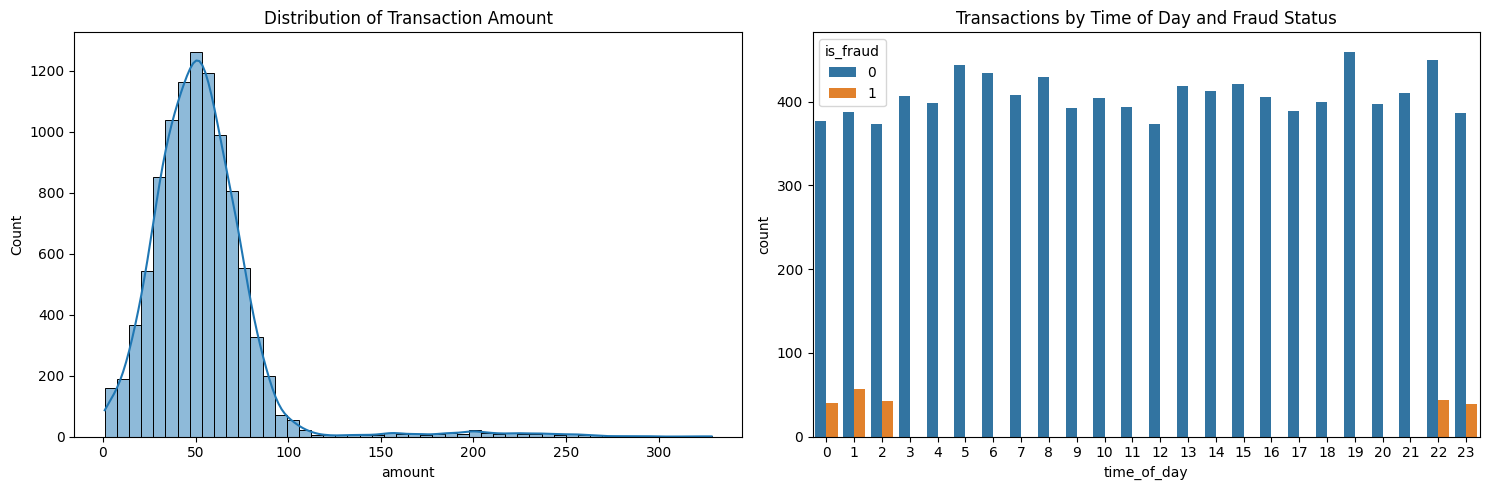

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df['amount'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Transaction Amount')

sns.countplot(x='time_of_day', hue='is_fraud', data=df, ax=axes[1])
axes[1].set_title('Transactions by Time of Day and Fraud Status')
plt.tight_layout()
plt.show()

In [3]:

FRAUD_THRESHOLD_AMOUNT = 150
NIGHT_HOURS = [0, 1, 2, 22, 23]

df['is_flagged_by_rule'] = 0
df.loc[df['amount'] > FRAUD_THRESHOLD_AMOUNT, 'is_flagged_by_rule'] = 1
df.loc[df['time_of_day'].isin(NIGHT_HOURS), 'is_flagged_by_rule'] = 1

print("Transactions flagged by rule:")
display(df[df['is_flagged_by_rule'] == 1].head())


true_positives = df[(df['is_fraud'] == 1) & (df['is_flagged_by_rule'] == 1)].shape[0]
false_positives = df[(df['is_fraud'] == 0) & (df['is_flagged_by_rule'] == 1)].shape[0]
false_negatives = df[(df['is_fraud'] == 1) & (df['is_flagged_by_rule'] == 0)].shape[0]
true_negatives = df[(df['is_fraud'] == 0) & (df['is_flagged_by_rule'] == 0)].shape[0]

precision = true_positives / (true_positives + false_positives) if (true_positives + false_positives) > 0 else 0
recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0
accuracy = (true_positives + true_negatives) / num_transactions

print(f"\nTrue Positives (actual fraud, flagged): {true_positives}")
print(f"False Positives (not fraud, flagged): {false_positives}")
print(f"False Negatives (actual fraud, not flagged): {false_negatives}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"Accuracy: {accuracy:.2f}")

Transactions flagged by rule:


,transaction_id,user_id,amount,location,time_of_day,is_fraud,is_flagged_by_rule
3,3,271,24.62,DE,22,0,1
4,4,107,28.73,AU,2,0,1
8,8,615,57.22,US,23,0,1
12,12,331,58.47,US,22,0,1
14,14,88,41.71,AU,22,0,1



True Positives (actual fraud, flagged): 222
False Positives (not fraud, flagged): 1975
False Negatives (actual fraud, not flagged): 0
Precision: 0.10
Recall: 1.00
Accuracy: 0.80


In [4]:
import pandas as pd
import numpy as np

np.random.seed(42)

num_records = 10000

start_time = pd.to_datetime('2023-01-01 00:00:00')
timestamps = [start_time + pd.Timedelta(minutes=i) for i in range(num_records)]

def generate_ip():
    return f"{np.random.randint(1, 255)}.{np.random.randint(0, 255)}.{np.random.randint(0, 255)}.{np.random.randint(1, 255)}"

source_ips = [generate_ip() for _ in range(num_records)]
destination_ips = [generate_ip() for _ in range(num_records)]

source_ports = np.random.randint(1024, 65535, num_records)
destination_ports = np.random.choice([80, 443, 21, 22, 23, 25, 53, 3389, np.random.randint(1024, 65535)], num_records)
protocols = np.random.choice(['TCP', 'UDP', 'ICMP'], num_records, p=[0.7, 0.2, 0.1])
packet_sizes = np.random.normal(500, 200, num_records).astype(int)
packet_sizes[packet_sizes < 50] = 50
event_types = np.random.choice(['normal', 'scan', 'DDoS', 'malware_traffic', 'phishing_attempt'], num_records, p=[0.85, 0.05, 0.03, 0.05, 0.02])
alerts = (event_types != 'normal').astype(int)

scan_indices = np.where(event_types == 'scan')[0]
if len(scan_indices) > 0:
    unique_scan_ip = generate_ip()
    for i in scan_indices:
        source_ips[i] = unique_scan_ip
        destination_ports[i] = np.random.randint(1, 1024)


ddos_indices = np.where(event_types == 'DDoS')[0]
if len(ddos_indices) > 0:
    packet_sizes[ddos_indices] = np.random.normal(1500, 300, len(ddos_indices)).astype(int)



cyber_df = pd.DataFrame({
    'timestamp': timestamps,
    'source_ip': source_ips,
    'destination_ip': destination_ips,
    'source_port': source_ports,
    'destination_port': destination_ports,
    'protocol': protocols,
    'packet_size': packet_sizes,
    'event_type': event_types,
    'alert': alerts
})

print("Generated synthetic cybersecurity dataset:")
display(cyber_df.head())
print(f"Total alerts generated: {cyber_df['alert'].sum()}")

Generated synthetic cybersecurity dataset:


,timestamp,source_ip,destination_ip,source_port,destination_port,protocol,packet_size,event_type,alert
0,2023-01-01 00:00:00,103.179.92.15,116.252.243.15,62285,25,TCP,820,normal,0
1,2023-01-01 00:01:00,107.71.188.21,184.34.38.24,56488,21,TCP,400,normal,0
2,2023-01-01 00:02:00,103.121.210.215,8.42.169.84,36942,22,TCP,418,normal,0
3,2023-01-01 00:03:00,75.202.87.117,169.46.25.180,62534,37046,UDP,359,normal,0
4,2023-01-01 00:04:00,100.103.151.131,216.149.132.143,21766,53,TCP,540,normal,0


Total alerts generated: 1541


In [14]:
print("\n--- DataFrame Info ---")
cyber_df.info()

print("\n--- Descriptive Statistics for Numerical Columns ---")
display(cyber_df.describe())


--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   timestamp         10000 non-null  datetime64[ns]
 1   source_ip         10000 non-null  object        
 2   destination_ip    10000 non-null  object        
 3   source_port       10000 non-null  int64         
 4   destination_port  10000 non-null  int64         
 5   protocol          10000 non-null  object        
 6   packet_size       10000 non-null  int64         
 7   event_type        10000 non-null  object        
 8   alert             10000 non-null  int64         
dtypes: datetime64[ns](1), int64(4), object(4)
memory usage: 703.3+ KB

--- Descriptive Statistics for Numerical Columns ---


,timestamp,source_port,destination_port,packet_size,alert
count,10000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2023-01-04 11:19:30,33399.107200,4438.525400,533.053600,0.154100
min,2023-01-01 00:00:00,1026.000000,1.000000,50.000000,0.000000
25%,2023-01-02 17:39:45,17673.250000,23.000000,370.000000,0.000000
50%,2023-01-04 11:19:30,33385.500000,53.000000,511.000000,0.000000
75%,2023-01-06 04:59:15,49559.500000,443.000000,653.000000,0.000000
max,2023-01-07 22:39:00,65531.000000,37046.000000,2207.000000,1.000000
std,NaN,18644.107609,11389.672064,266.994394,0.361063


### Exploratory Data Analysis (EDA) of `cyber_df`

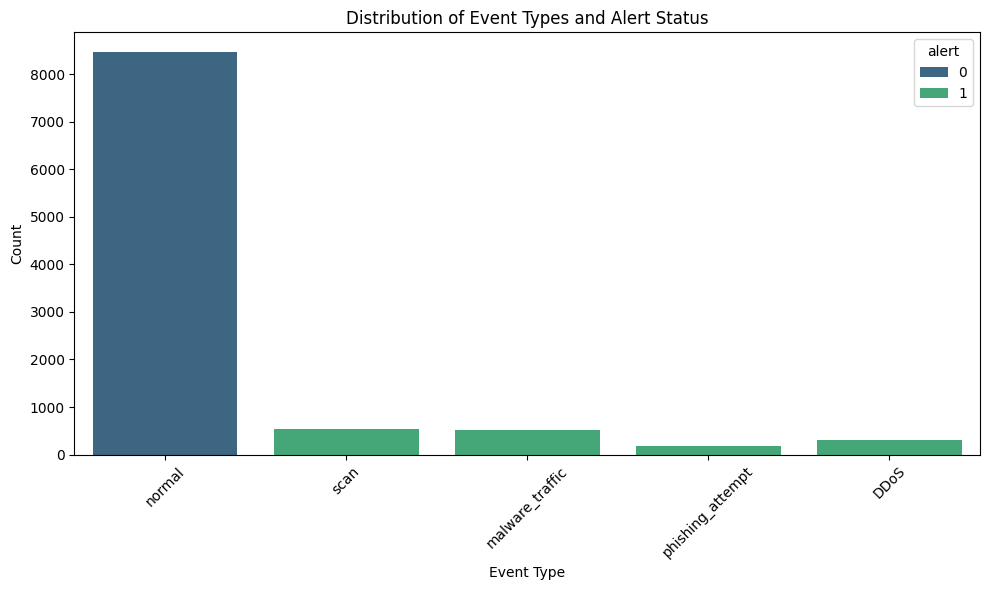

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.countplot(x='event_type', hue='alert', data=cyber_df, palette='viridis')
plt.title('Distribution of Event Types and Alert Status')
plt.xlabel('Event Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

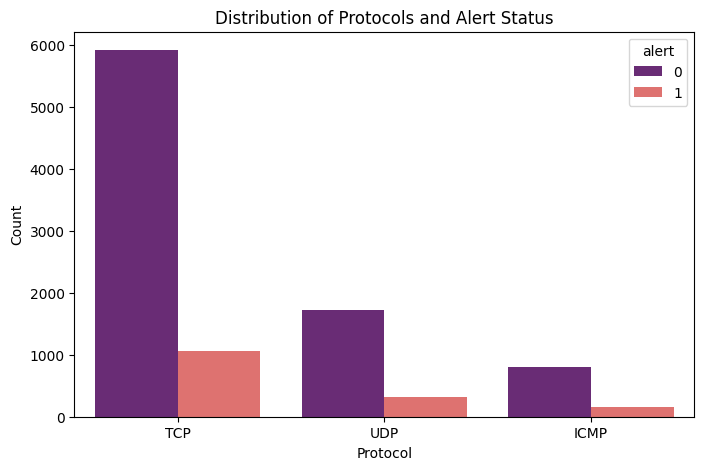

In [16]:

plt.figure(figsize=(8, 5))
sns.countplot(x='protocol', hue='alert', data=cyber_df, palette='magma')
plt.title('Distribution of Protocols and Alert Status')
plt.xlabel('Protocol')
plt.ylabel('Count')
plt.show()

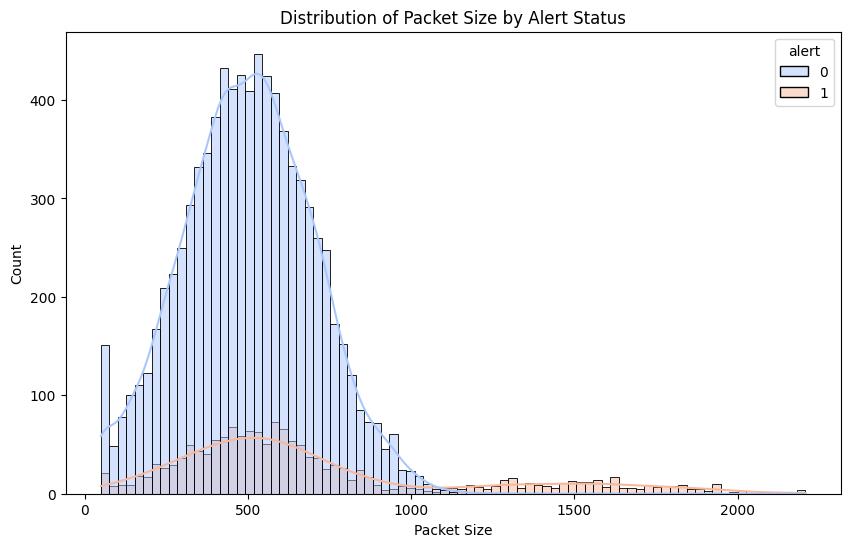

In [17]:

plt.figure(figsize=(10, 6))
sns.histplot(data=cyber_df, x='packet_size', hue='alert', kde=True, palette='coolwarm')
plt.title('Distribution of Packet Size by Alert Status')
plt.xlabel('Packet Size')
plt.ylabel('Count')
plt.show()

In [18]:

top_source_ips_alerts = cyber_df[cyber_df['alert'] == 1]['source_ip'].value_counts().nlargest(10)
print("Top 10 Source IPs associated with Alerts:")
display(top_source_ips_alerts)
top_dest_ips_alerts = cyber_df[cyber_df['alert'] == 1]['destination_ip'].value_counts().nlargest(10)
print("\nTop 10 Destination IPs associated with Alerts:")
display(top_dest_ips_alerts)

Top 10 Source IPs associated with Alerts:


,count
source_ip,
240.112.41.234,532
130.254.206.87,1
245.47.44.182,1
100.99.212.46,1
174.125.45.206,1
46.178.189.163,1
15.124.160.87,1
158.68.203.135,1
153.211.56.66,1



Top 10 Destination IPs associated with Alerts:


,count
destination_ip,
97.152.16.223,1
72.208.128.118,1
173.238.236.33,1
141.193.56.171,1
22.123.132.135,1
158.61.184.165,1
124.169.136.185,1
217.239.44.160,1
19.227.226.141,1


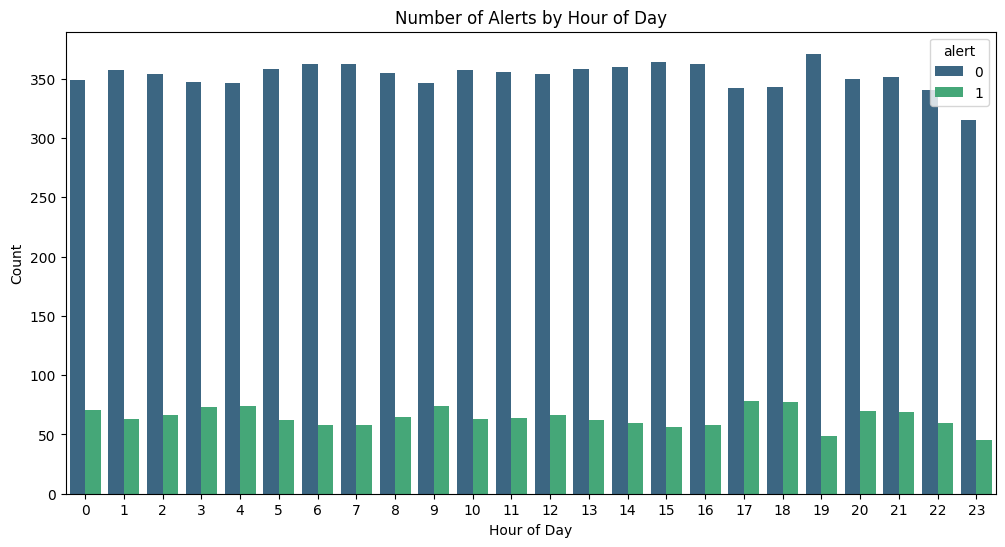

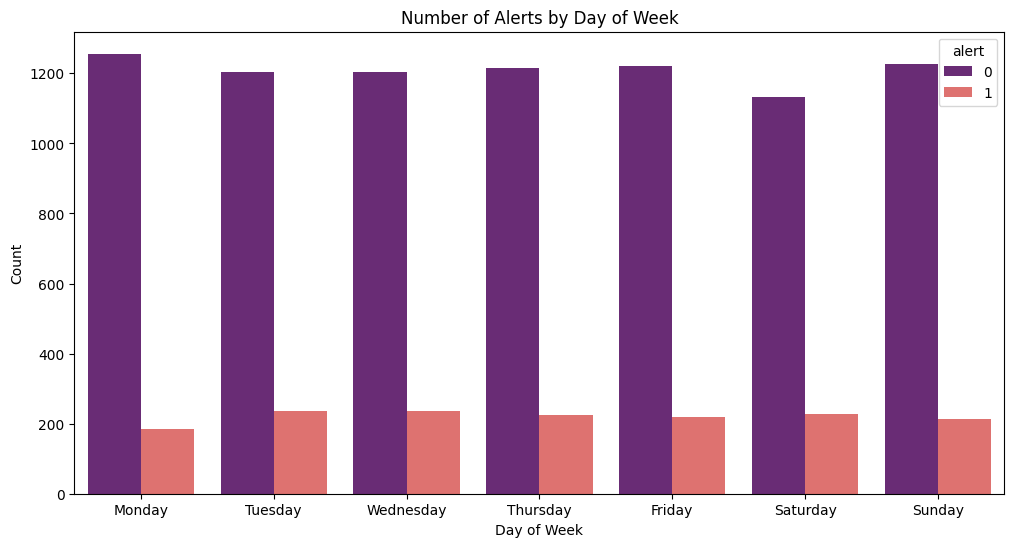

In [19]:

cyber_df['hour'] = cyber_df['timestamp'].dt.hour
cyber_df['day_of_week'] = cyber_df['timestamp'].dt.day_name()
plt.figure(figsize=(12, 6))
sns.countplot(x='hour', hue='alert', data=cyber_df, palette='viridis')
plt.title('Number of Alerts by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Count')
plt.show()
plt.figure(figsize=(12, 6))
sns.countplot(x='day_of_week', hue='alert', data=cyber_df, palette='magma', order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
plt.title('Number of Alerts by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Count')
plt.show()

In [23]:
num_records_new = 15000

start_time_new = pd.to_datetime('2024-03-01 00:00:00')
timestamps_new = [start_time_new + pd.Timedelta(seconds=i*5) for i in range(num_records_new)] # 5-second intervals

def generate_ip():
    return f"{np.random.randint(1, 255)}.{np.random.randint(0, 255)}.{np.random.randint(0, 255)}.{np.random.randint(1, 255)}"

source_ips_new = [generate_ip() for _ in range(num_records_new)]
destination_ips_new = [generate_ip() for _ in range(num_records_new)]

source_ports_new = np.random.randint(1024, 65535, num_records_new)
destination_ports_new = np.random.choice([80, 443, 21, 22, 23, 25, 53, 3389, 8080, np.random.randint(1024, 65535)], num_records_new)
protocols_new = np.random.choice(['TCP', 'UDP', 'ICMP', 'HTTP', 'HTTPS'], num_records_new, p=[0.6, 0.2, 0.1, 0.05, 0.05])
packet_sizes_new = np.random.normal(700, 300, num_records_new).astype(int)
packet_sizes_new[packet_sizes_new < 64] = 64
packet_sizes_new[packet_sizes_new > 1500] = 1500


all_event_types = ['normal', 'scan', 'DDoS', 'malware_traffic', 'phishing_attempt'] + attack_types

event_types_new = np.random.choice(all_event_types, num_records_new, p=[0.75, 0.05, 0.05, 0.05, 0.05, 0.03, 0.02])
severities_new = []
alerts_new = []
for etype in event_types_new:
    if etype == 'normal' or etype == 'normal login':
        severities_new.append(0)
        alerts_new.append(0)
    elif etype == 'brute force':
        severities_new.append(severity['medium'])
        alerts_new.append(1)
    elif etype in ['scan', 'phishing_attempt']:
        severities_new.append(severity['low'])
        alerts_new.append(1)
    elif etype in ['malware_traffic', 'DDoS']:
        severities_new.append(severity['high'])
        alerts_new.append(1)
    else:
        severities_new.append(0)
        alerts_new.append(0)


brute_force_indices = np.where(event_types_new == 'brute force')[0]
if len(brute_force_indices) > 0:

    brute_force_source_ips = [generate_ip() for _ in range(min(5, len(brute_force_indices)))]
    for i, idx in enumerate(brute_force_indices):
        source_ips_new[idx] = brute_force_source_ips[i % len(brute_force_source_ips)]
        destination_ports_new[idx] = np.random.choice([21, 22, 23, 3389])
        packet_sizes_new[idx] = np.random.randint(64, 200)

new_cyber_df = pd.DataFrame({
    'timestamp': timestamps_new,
    'source_ip': source_ips_new,
    'destination_ip': destination_ips_new,
    'source_port': source_ports_new,
    'destination_port': destination_ports_new,
    'protocol': protocols_new,
    'packet_size': packet_sizes_new,
    'event_type': event_types_new,
    'severity': severities_new,
    'alert': alerts_new
})

print("Generated new simulated cybersecurity dataset:")
display(new_cyber_df.head())
print(f"Total alerts generated in new dataset: {new_cyber_df['alert'].sum()}")
print(f"Distribution of event types in new dataset:\n{new_cyber_df['event_type'].value_counts()}")

Generated new simulated cybersecurity dataset:


,timestamp,source_ip,destination_ip,source_port,destination_port,protocol,packet_size,event_type,severity,alert
0,2024-03-01 00:00:00,74.186.229.15,228.151.109.167,48346,443,UDP,1038,normal,0,0
1,2024-03-01 00:00:05,4.126.59.213,149.234.105.35,39422,13989,HTTP,64,normal,0,0
2,2024-03-01 00:00:10,135.165.139.178,28.75.22.146,11352,443,TCP,601,normal,0,0
3,2024-03-01 00:00:15,108.171.217.203,184.133.194.109,49318,53,UDP,564,normal,0,0
4,2024-03-01 00:00:20,153.21.249.110,242.20.137.152,64880,25,TCP,682,scan,1,1


Total alerts generated in new dataset: 2954
Distribution of event types in new dataset:
event_type
normal              11322
scan                  785
DDoS                  740
malware_traffic       724
phishing_attempt      705
normal login          438
 brute force          286
Name: count, dtype: int64


JEHANABAD CYBERSECURITY ATTACK DATASET
Incident_ID       Date  Location        Attack_Type         Target  Amount_Lost        Channel
      JH001 2026-06-01 Jehanabad          UPI Fraud     Individual        25000            UPI
      JH002 2026-06-04 Jehanabad          KYC Fraud     Individual       148000     Phone Call
      JH003 2026-06-08 Jehanabad          OTP Fraud     Individual        14000            SMS
      JH004 2026-06-11 Jehanabad Bank Account Fraud     PDS Seller        71000 Mobile Banking
      JH005 2026-06-15 Jehanabad           Job Scam        Student        50000       WhatsApp
      JH006 2026-06-18 Jehanabad           Job Scam     Individual       200000       WhatsApp
      JH007 2026-06-22 Jehanabad          UPI Fraud     Individual        40000            UPI
      JH008 2026-07-02 Jehanabad     Digital Arrest     Individual        75000     Video Call
      JH009 2026-07-09 Jehanabad          KYC Fraud Senior Citizen        90000     Phone Call
      JH010

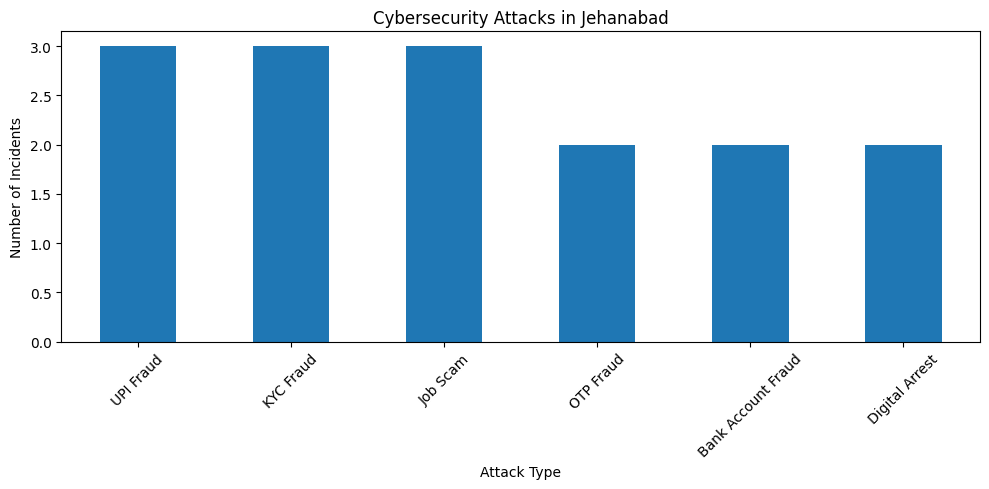

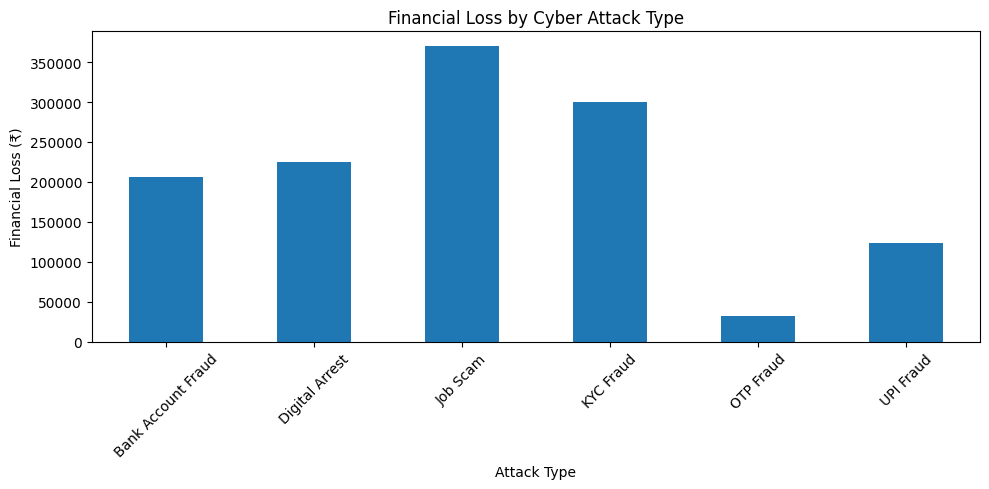


Attack Channel Frequency:
Channel
UPI               3
Phone Call        3
WhatsApp          3
SMS               2
Mobile Banking    2
Video Call        2
Name: count, dtype: int64

Dataset saved successfully as:
jehanabad_cybersecurity_dataset.csv


In [28]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Incident_ID": [
        "JH001", "JH002", "JH003", "JH004", "JH005",
        "JH006", "JH007", "JH008", "JH009", "JH010",
        "JH011", "JH012", "JH013", "JH014", "JH015"
    ],

    "Date": [
        "2026-06-01", "2026-06-04", "2026-06-08",
        "2026-06-11", "2026-06-15", "2026-06-18",
        "2026-06-22", "2026-07-02", "2026-07-09",
        "2026-07-17", "2026-08-03", "2026-08-12",
        "2026-08-21", "2026-09-01", "2026-09-04"
    ],

    "Location": [
        "Jehanabad", "Jehanabad", "Jehanabad",
        "Jehanabad", "Jehanabad", "Jehanabad",
        "Jehanabad", "Jehanabad", "Jehanabad",
        "Jehanabad", "Jehanabad", "Jehanabad",
        "Jehanabad", "Jehanabad", "Jehanabad"
    ],

    "Attack_Type": [
        "UPI Fraud", "KYC Fraud", "OTP Fraud",
        "Bank Account Fraud", "Job Scam", "Job Scam",
        "UPI Fraud", "Digital Arrest", "KYC Fraud",
        "OTP Fraud", "UPI Fraud", "Digital Arrest",
        "Job Scam", "KYC Fraud", "Bank Account Fraud"
    ],

    "Target": [
        "Individual", "Individual", "Individual",
        "PDS Seller", "Student", "Individual",
        "Individual", "Individual", "Senior Citizen",
        "Individual", "Individual", "Individual",
        "Student", "Individual", "Individual"
    ],

    "Amount_Lost": [
        25000, 148000, 14000, 71000, 50000,
        200000, 40000, 75000, 90000, 18000,
        58000, 150000, 120000, 62000, 135000
    ],

    "Channel": [
        "UPI", "Phone Call", "SMS", "Mobile Banking",
        "WhatsApp", "WhatsApp", "UPI", "Video Call",
        "Phone Call", "SMS", "UPI", "Video Call",
        "WhatsApp", "Phone Call", "Mobile Banking"
    ]
}

df = pd.DataFrame(data)

df["Date"] = pd.to_datetime(df["Date"])



print("=" * 50)
print("JEHANABAD CYBERSECURITY ATTACK DATASET")
print("=" * 50)

print(df.to_string(index=False))



print("\nTotal Number of Incidents:", len(df))

print("Total Financial Loss: ₹", df["Amount_Lost"].sum())

print("Average Financial Loss: ₹", round(df["Amount_Lost"].mean(), 2))



print("\nAttack Type Frequency:")
print(df["Attack_Type"].value_counts())

print("\nFinancial Loss by Attack Type:")
print(
    df.groupby("Attack_Type")["Amount_Lost"]
    .sum()
    .sort_values(ascending=False)
)



most_common = df["Attack_Type"].value_counts().idxmax()

print("\nMost Common Attack Type:", most_common)



plt.figure(figsize=(10, 5))

df["Attack_Type"].value_counts().plot(kind="bar")

plt.title("Cybersecurity Attacks in Jehanabad")
plt.xlabel("Attack Type")
plt.ylabel("Number of Incidents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



loss = df.groupby("Attack_Type")["Amount_Lost"].sum()

plt.figure(figsize=(10, 5))

loss.plot(kind="bar")

plt.title("Financial Loss by Cyber Attack Type")
plt.xlabel("Attack Type")
plt.ylabel("Financial Loss (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



print("\nAttack Channel Frequency:")
print(df["Channel"].value_counts())



df.to_csv("jehanabad_cybersecurity_dataset.csv", index=False)

print("\nDataset saved successfully as:")
print("jehanabad_cybersecurity_dataset.csv")